# Capítulo 5 · Regresión lineal

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/riosinda/ml-course/blob/main/notebooks/lectures/chapter_05/02_regresion_lineal.ipynb)

**Aprendizaje supervisado · Parte 2: predicción numérica**

### 📚 Índice
1. Regresión lineal
2. Dataset California Housing (EDA)
3. Limpieza y preparación
4. Regresión lineal simple
5. Regresión lineal múltiple
6. Métricas de error y $R^2$
7. Comparación de modelos
8. Chuleta resumen

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn import set_config
from sklearn.linear_model import Lasso, LinearRegression, RANSACRegressor, Ridge
from sklearn.metrics import (mean_absolute_error, mean_absolute_percentage_error, mean_squared_error,
                             r2_score, root_mean_squared_error)
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

# Que scikit-learn devuelva DataFrames (con nombres de columna) en lugar de arrays de NumPy
set_config(transform_output="pandas")
sns.set_theme(style="whitegrid")

# Semilla para que los resultados sean reproducibles
SEED = 42
np.random.seed(SEED)

# Carpeta data/ en la raíz del repo: subimos de carpeta en carpeta hasta dar con pyproject.toml
raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), Path.cwd())
DATA_DIR = raiz / "data"

---
## 1. Regresión lineal

$$Y = \beta_0 + \beta_1 X_1 + \dots + \beta_k X_k + \varepsilon$$

OLS elige los $\beta$ que minimizan $\sum (y_i - \hat{y}_i)^2$.

---
## 2. El dataset California Housing

Cada fila es un distrito de California (censo de 1990). **Target:** `MedHouseVal`, en cientos de miles de dólares. `MedInc` está en decenas de miles de dólares.

> Boston Housing se eliminó de scikit-learn en la versión 1.2 por problemas éticos en una de sus variables.

> 💡 Si no tienes `data/california_housing.csv`: `uv run python scripts/download_data.py`

In [2]:
df = pd.read_csv(DATA_DIR / "california_housing.csv")
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


### 2.1 Vistazo general

In [3]:
print("Filas y columnas:", df.shape)
df.info()

Filas y columnas: (20640, 9)
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [4]:
df.describe().round(2)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00
mean,3.87,28.64,5.43,1.10,1425.48,3.07,35.63,-119.57,2.07
std,1.90,12.59,2.47,0.47,1132.46,10.39,2.14,2.00,1.15
min,0.50,1.00,0.85,0.33,3.00,0.69,32.54,-124.35,0.15
25%,2.56,18.00,4.44,1.01,787.00,2.43,33.93,-121.80,1.20
50%,3.53,29.00,5.23,1.05,1166.00,2.82,34.26,-118.49,1.80
75%,4.74,37.00,6.05,1.10,1725.00,3.28,37.71,-118.01,2.65
max,15.00,52.00,141.91,34.07,35682.00,1243.33,41.95,-114.31,5.00


Valores extremos en `AveRooms`, `AveBedrms`, `Population` y `AveOccup`.

### 2.2 Distribución de cada variable

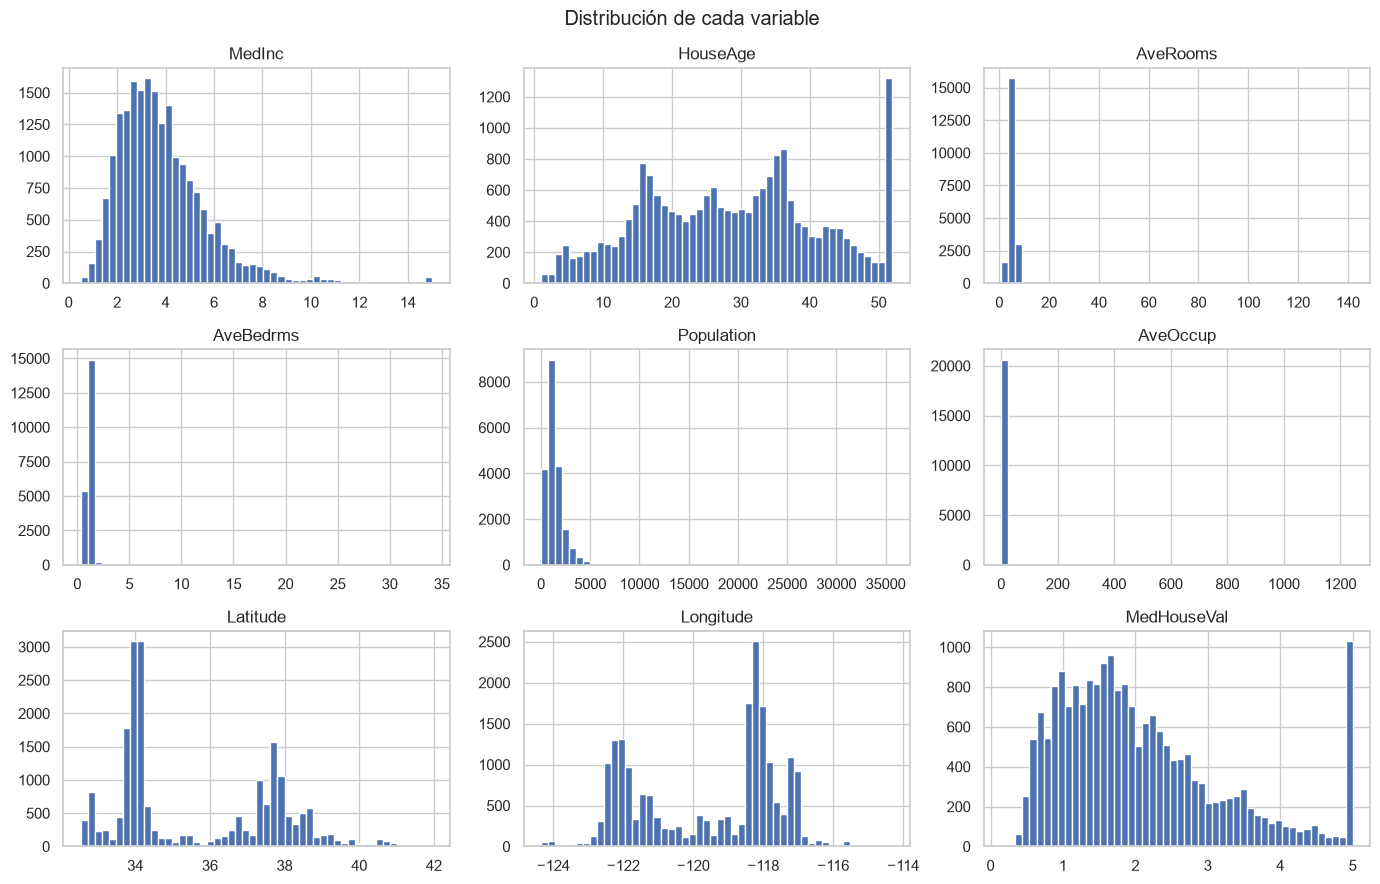

In [5]:
df.hist(bins=50, figsize=(14, 9))
plt.suptitle("Distribución de cada variable")
plt.tight_layout()
plt.show()

### 2.3 El target tiene un tope

Valor máximo de MedHouseVal: 5.00001
Distritos con ese valor:      965


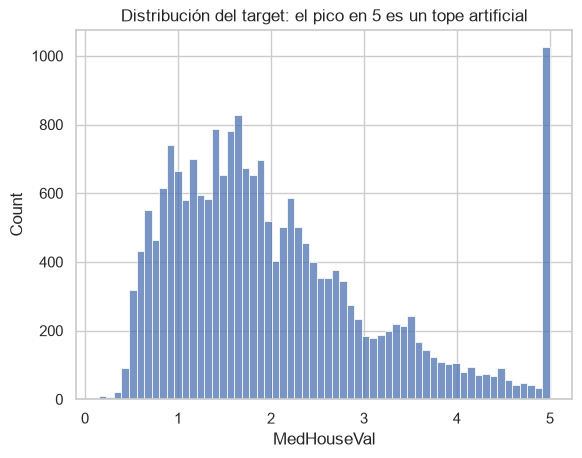

In [6]:
print("Valor máximo de MedHouseVal:", df["MedHouseVal"].max())
print("Distritos con ese valor:     ", (df["MedHouseVal"] == df["MedHouseVal"].max()).sum())

ax = sns.histplot(data=df, x="MedHouseVal", bins=60)
ax.set_title("Distribución del target: el pico en 5 es un tope artificial")
plt.show()

Los valores por encima de 500 000 $ se guardaron como 500 001 $: el target está **censurado**.

### 2.4 Correlaciones

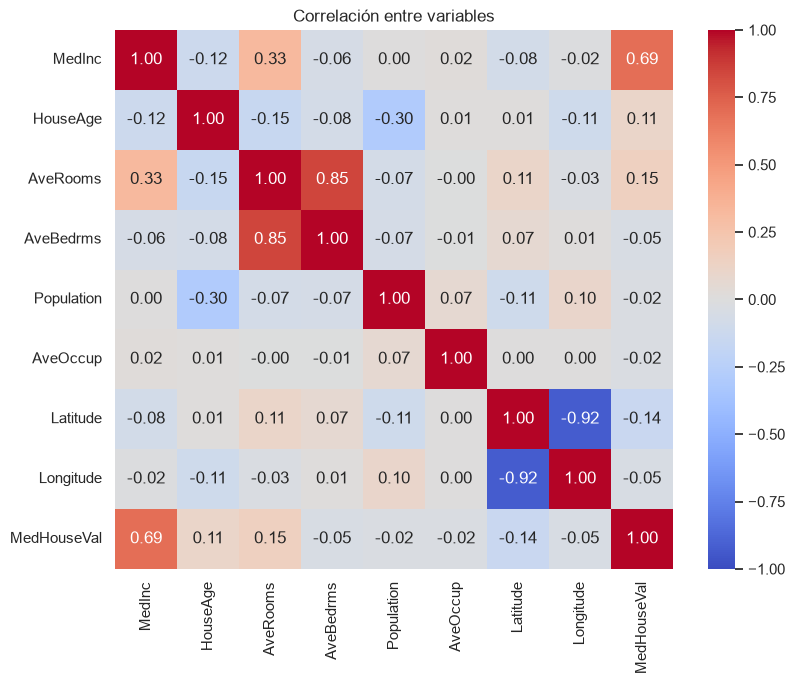

In [7]:
correlaciones = df.corr()

plt.figure(figsize=(9, 7))
sns.heatmap(correlaciones, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlación entre variables")
plt.show()

`MedInc` es la variable más correlacionada con el precio. `Latitude`/`Longitude` y `AveRooms`/`AveBedrms` están muy correlacionadas entre sí (**multicolinealidad**).

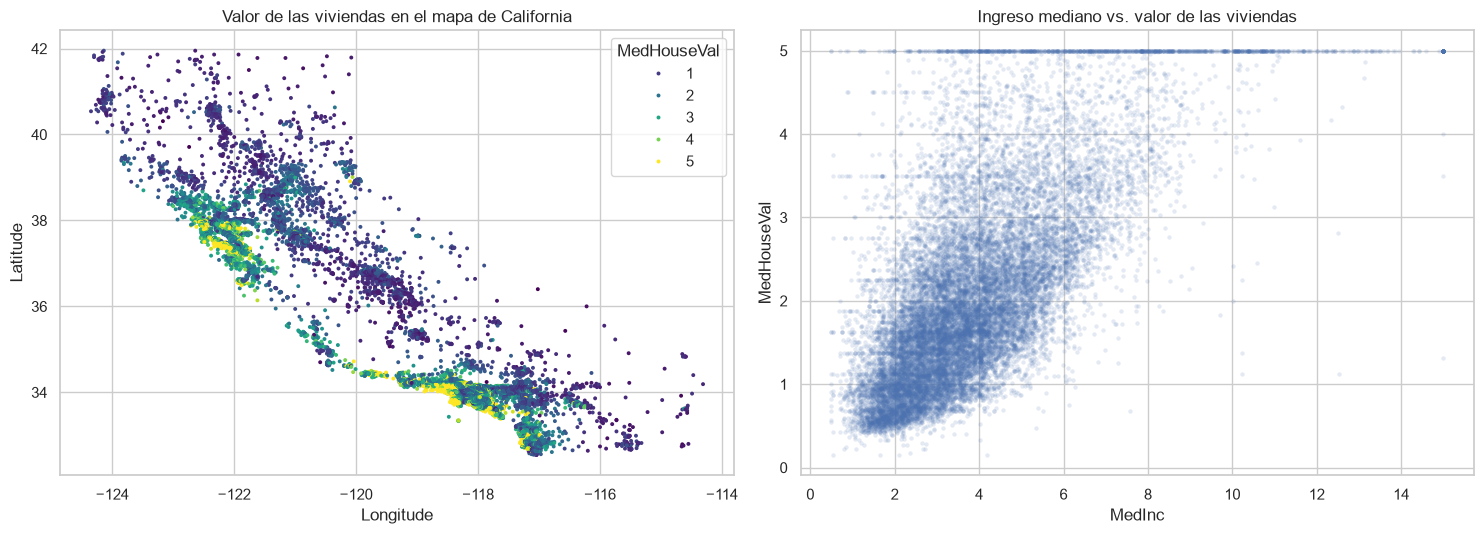

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

sns.scatterplot(data=df, x="Longitude", y="Latitude", hue="MedHouseVal", palette="viridis",
                s=8, linewidth=0, ax=axes[0])
axes[0].set_title("Valor de las viviendas en el mapa de California")

sns.scatterplot(data=df, x="MedInc", y="MedHouseVal", alpha=0.15, s=10, linewidth=0, ax=axes[1])
axes[1].set_title("Ingreso mediano vs. valor de las viviendas")
plt.tight_layout()
plt.show()

La ubicación importa (la costa es más cara), pero no de forma lineal.

---
## 3. Limpieza y preparación

### 3.1 Nulos y duplicados

In [9]:
print("Valores nulos por columna:")
print(df.isna().sum())
print("\nFilas duplicadas:", df.duplicated().sum())

Valores nulos por columna:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Filas duplicadas: 0


### 3.2 Quitamos los distritos con el target censurado

En el censo, toda vivienda de más de 500 000  se registró como 500 001  (`5.00001`): una casa de 600 000  y otra de 2 millones quedan con el mismo valor. Ese dato está **censurado**.

Si los dejamos, la regresión aprende algo falso (que el precio deja de subir a partir de cierto ingreso). Los quitamos con `< 5`, que elimina también los 27 distritos que valen exactamente 5.0.

**Limitación:** el modelo solo servirá para viviendas de menos de 500 000 .

In [10]:
df = df[df["MedHouseVal"] < 5].reset_index(drop=True)
print("Distritos que quedan:", len(df))

Distritos que quedan: 19648


### 3.3 Train y test

En regresión no se usa `stratify` (ni en el split ni en la validación cruzada: `KFold` en lugar de `StratifiedKFold`).

In [11]:
X = df.drop(columns="MedHouseVal")
y = df["MedHouseVal"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)

# Validación cruzada que usaremos durante toda la clase
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (15718, 8) | Test: (3930, 8)


### 3.4 Outliers (IQR, límites calculados con train)

In [12]:
q1 = X_train.quantile(0.25)
q3 = X_train.quantile(0.75)
iqr = q3 - q1
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

es_outlier = (X_train < limite_inferior) | (X_train > limite_superior)
es_outlier.sum()

MedInc         297
HouseAge         0
AveRooms       361
AveBedrms     1068
Population     919
AveOccup       524
Latitude         0
Longitude        0
dtype: int64

Recortamos (*capping*) con los límites de train; en test usamos los mismos límites.

In [13]:
X_train_antes = X_train.copy()   # solo para comparar en la gráfica

X_train = X_train.clip(lower=limite_inferior, upper=limite_superior, axis=1)
X_test = X_test.clip(lower=limite_inferior, upper=limite_superior, axis=1)

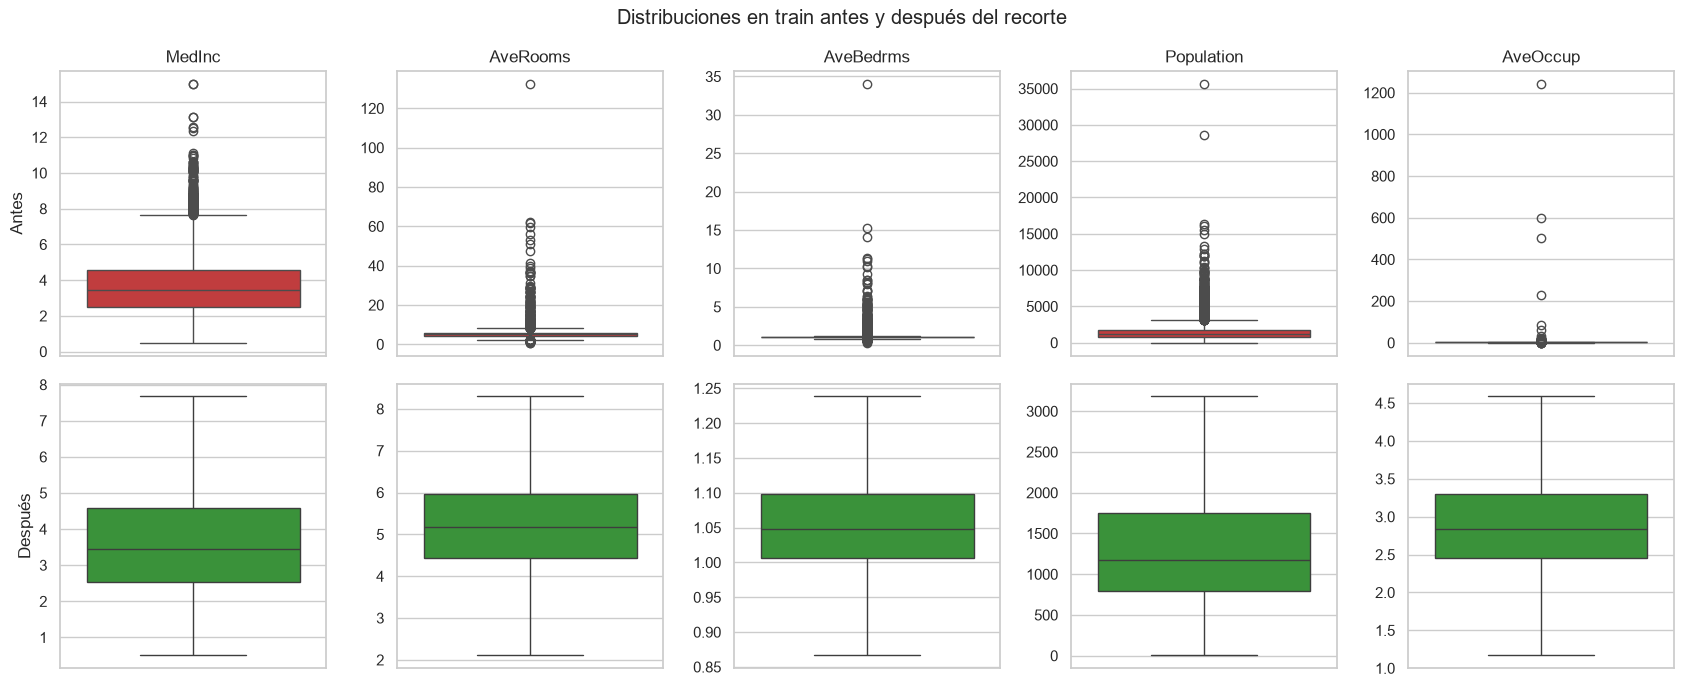

In [14]:
variables_con_outliers = ["MedInc", "AveRooms", "AveBedrms", "Population", "AveOccup"]

fig, axes = plt.subplots(2, 5, figsize=(17, 7))
for j, variable in enumerate(variables_con_outliers):
    sns.boxplot(y=X_train_antes[variable], ax=axes[0, j], color="tab:red")
    sns.boxplot(y=X_train[variable], ax=axes[1, j], color="tab:green")
    axes[0, j].set_title(variable)
    axes[0, j].set_ylabel("Antes" if j == 0 else "")
    axes[1, j].set_ylabel("Después" if j == 0 else "")
fig.suptitle("Distribuciones en train antes y después del recorte")
plt.tight_layout()
plt.show()

---
## 4. Regresión lineal simple

$\text{MedHouseVal} = \beta_0 + \beta_1 \cdot \text{MedInc}$

### 4.1 Entrenamiento

In [15]:
modelo_simple = LinearRegression()
modelo_simple.fit(X_train[["MedInc"]], y_train)   # doble corchete: X debe ser una tabla, no una columna

beta_0 = modelo_simple.intercept_
beta_1 = modelo_simple.coef_[0]
print(f"Intercepto  β0 = {beta_0:.3f}")
print(f"Pendiente   β1 = {beta_1:.3f}")

Intercepto  β0 = 0.397
Pendiente   β1 = 0.416


### 4.2 Interpretación de los coeficientes

In [16]:
print(f"Por cada 10 000 $ más de ingreso, el valor sube unos {beta_1 * 100_000:,.0f} $")

Por cada 10 000 $ más de ingreso, el valor sube unos 41,610 $


### 4.3 La recta y los residuos

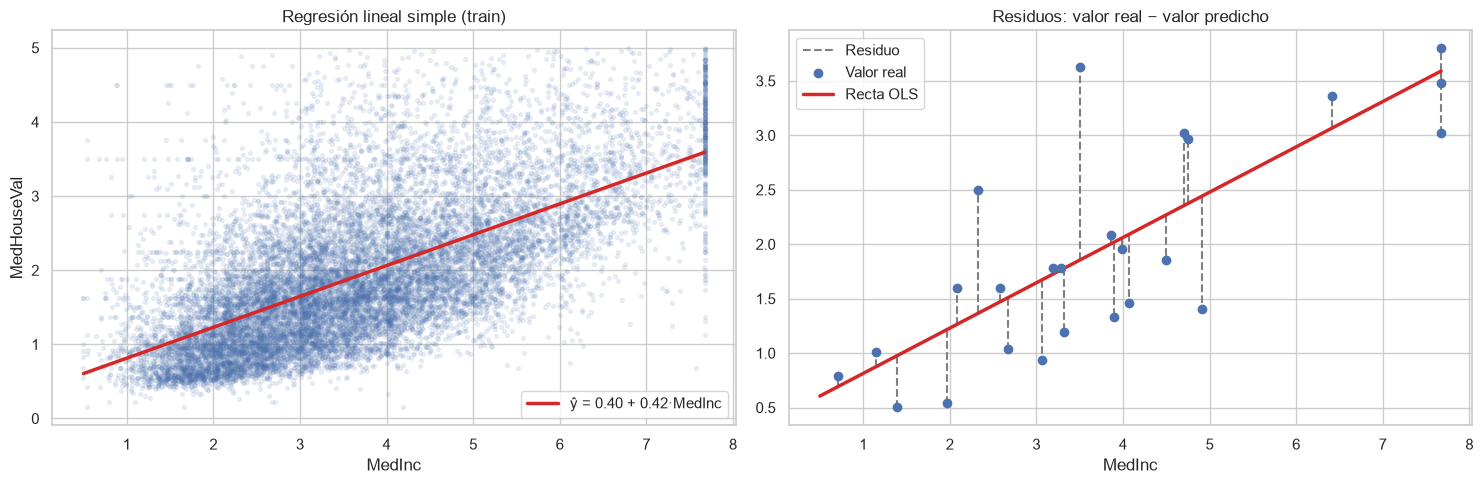

In [17]:
recta_x = pd.DataFrame({"MedInc": np.linspace(X_train["MedInc"].min(), X_train["MedInc"].max(), 100)})
recta_y = modelo_simple.predict(recta_x)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].scatter(X_train["MedInc"], y_train, alpha=0.1, s=8)
axes[0].plot(recta_x["MedInc"], recta_y, color="tab:red", linewidth=2.5, label=f"ŷ = {beta_0:.2f} + {beta_1:.2f}·MedInc")
axes[0].set_xlabel("MedInc")
axes[0].set_ylabel("MedHouseVal")
axes[0].set_title("Regresión lineal simple (train)")
axes[0].legend()

muestra = X_train[["MedInc"]].sample(25, random_state=SEED)
y_muestra = y_train.loc[muestra.index]
pred_muestra = modelo_simple.predict(muestra)
axes[1].vlines(muestra["MedInc"], pred_muestra, y_muestra, color="gray", linestyle="--", label="Residuo")
axes[1].scatter(muestra["MedInc"], y_muestra, zorder=3, label="Valor real")
axes[1].plot(recta_x["MedInc"], recta_y, color="tab:red", linewidth=2.5, label="Recta OLS")
axes[1].set_xlabel("MedInc")
axes[1].set_title("Residuos: valor real − valor predicho")
axes[1].legend()
plt.tight_layout()
plt.show()

### 4.4 Predicción

In [18]:
distritos_nuevos = pd.DataFrame({"MedInc": [2.0, 5.0, 8.0]})   # 20 000 $, 50 000 $ y 80 000 $
distritos_nuevos["valor_predicho"] = modelo_simple.predict(distritos_nuevos)

# A mano, con la ecuación de la recta: el resultado es el mismo
distritos_nuevos["a_mano"] = beta_0 + beta_1 * distritos_nuevos["MedInc"]
distritos_nuevos.round(3)

,MedInc,valor_predicho,a_mano
0,2.0,1.229,1.229
1,5.0,2.478,2.478
2,8.0,3.726,3.726


### 4.5 Evaluación en test

In [19]:
pred_simple = modelo_simple.predict(X_test[["MedInc"]])
print(f"R² en test:   {r2_score(y_test, pred_simple):.3f}")
print(f"RMSE en test: {root_mean_squared_error(y_test, pred_simple):.3f}  (cientos de miles de $)")

R² en test:   0.414
RMSE en test: 0.749  (cientos de miles de $)


---
## 5. Regresión lineal múltiple

Las 8 variables, estandarizadas para que los coeficientes sean comparables.

In [20]:
modelo_lineal = Pipeline([
    ("escalador", StandardScaler()),
    ("regresion", LinearRegression()),
])
modelo_lineal.fit(X_train, y_train)

pred_lineal = modelo_lineal.predict(X_test)
print(f"R² en test:   {r2_score(y_test, pred_lineal):.3f}   (regresión simple: {r2_score(y_test, pred_simple):.3f})")
print(f"RMSE en test: {root_mean_squared_error(y_test, pred_lineal):.3f}   (regresión simple: {root_mean_squared_error(y_test, pred_simple):.3f})")

R² en test:   0.621   (regresión simple: 0.414)
RMSE en test: 0.603   (regresión simple: 0.749)


### 5.1 Coeficientes estandarizados

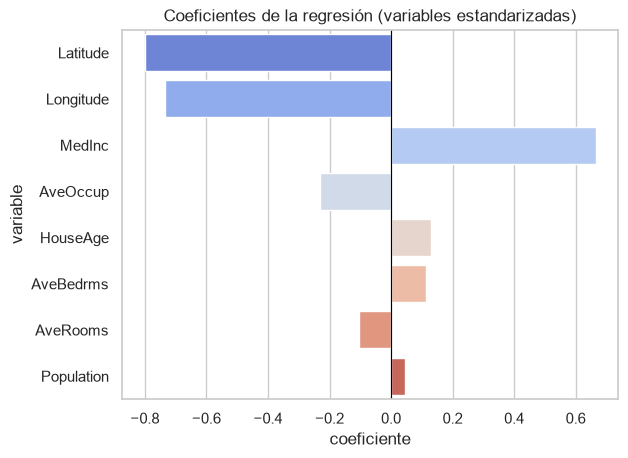

,variable,coeficiente
6,Latitude,-0.801
7,Longitude,-0.734
0,MedInc,0.665
5,AveOccup,-0.232
1,HouseAge,0.129
3,AveBedrms,0.115
2,AveRooms,-0.104
4,Population,0.045


In [21]:
coeficientes = pd.DataFrame({
    "variable": X_train.columns,
    "coeficiente": modelo_lineal.named_steps["regresion"].coef_,
}).sort_values("coeficiente", key=abs, ascending=False)

ax = sns.barplot(data=coeficientes, x="coeficiente", y="variable", hue="variable", palette="coolwarm")
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Coeficientes de la regresión (variables estandarizadas)")
plt.show()

coeficientes.round(3)

Coeficientes de variables muy correlacionadas (`Latitude`/`Longitude`) son difíciles de interpretar por separado.

---
## 6. Métricas de error y $R^2$

In [22]:
def metricas_regresion(y_real, y_pred, n_variables):
    "Métricas principales de una regresión."
    n = len(y_real)
    r2 = r2_score(y_real, y_pred)
    return {
        "MSE": mean_squared_error(y_real, y_pred),
        "RMSE": root_mean_squared_error(y_real, y_pred),
        "MAE": mean_absolute_error(y_real, y_pred),
        "MAPE": mean_absolute_percentage_error(y_real, y_pred),
        "R²": r2,
        "R² ajustado": 1 - (1 - r2) * (n - 1) / (n - n_variables - 1),
        "Correlación(y, ŷ)": np.corrcoef(y_real, y_pred)[0, 1],
    }


pd.DataFrame({
    "Simple (MedInc)": metricas_regresion(y_test, pred_simple, n_variables=1),
    "Múltiple (8 variables)": metricas_regresion(y_test, pred_lineal, n_variables=8),
}).round(3)

,Simple (MedInc),Múltiple (8 variables)
MSE,0.561,0.363
RMSE,0.749,0.603
MAE,0.574,0.455
MAPE,0.376,0.295
R²,0.414,0.621
R² ajustado,0.414,0.620
"Correlación(y, ŷ)",0.644,0.788


### 6.1 Real vs. predicho

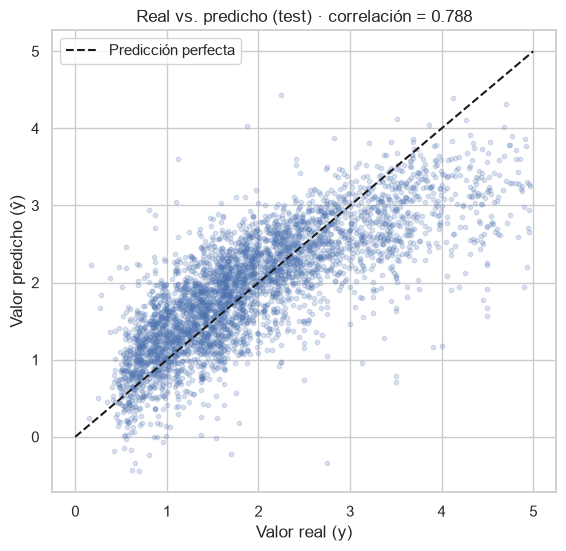

In [23]:
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(y_test, pred_lineal, alpha=0.2, s=10)
ax.plot([0, 5], [0, 5], "k--", label="Predicción perfecta")
ax.set_xlabel("Valor real (y)")
ax.set_ylabel("Valor predicho (ŷ)")
ax.set_title(f"Real vs. predicho (test) · correlación = {np.corrcoef(y_test, pred_lineal)[0, 1]:.3f}")
ax.legend()
plt.show()

---
## 7. Comparación de modelos

Mismos datos, mismo preprocesamiento, distinto modelo. Validación cruzada en train y evaluación en test.

In [24]:
modelos = {
    "Simple (MedInc)": LinearRegression(),
    "Lineal múltiple": modelo_lineal,
    "Ridge": Pipeline([("escalador", StandardScaler()), ("regresion", Ridge(alpha=1.0))]),
    "Lasso": Pipeline([("escalador", StandardScaler()), ("regresion", Lasso(alpha=0.01))]),
    "Polinomial (grado 2)": Pipeline([
        ("escalador", StandardScaler()),
        ("poli", PolynomialFeatures(degree=2, include_bias=False)),
        ("escalador_poli", StandardScaler()),
        ("regresion", LinearRegression()),
    ]),
    "RANSAC": Pipeline([("escalador", StandardScaler()),
                        ("regresion", RANSACRegressor(LinearRegression(), random_state=SEED))]),
}

filas = []
predicciones = {}
for nombre, modelo in modelos.items():
    columnas = ["MedInc"] if nombre.startswith("Simple") else list(X_train.columns)
    cv_res = cross_validate(modelo, X_train[columnas], y_train, cv=cv,
                            scoring="neg_root_mean_squared_error", return_train_score=True)
    modelo.fit(X_train[columnas], y_train)
    pred = modelo.predict(X_test[columnas])
    fila = {"modelo": nombre,
            "RMSE train (CV)": -cv_res["train_score"].mean(),
            "RMSE validación (CV)": -cv_res["test_score"].mean(),
            "RMSE validación (desv.)": cv_res["test_score"].std()}
    fila.update({f"{metrica} test": valor
                 for metrica, valor in metricas_regresion(y_test, pred, n_variables=len(columnas)).items()})
    filas.append(fila)
    predicciones[nombre] = pred

reporte = pd.DataFrame(filas).set_index("modelo")
reporte.drop(columns=["MSE test", "R² ajustado test"]).round(3)

,RMSE train (CV),RMSE validación (CV),RMSE validación (desv.),RMSE test,MAE test,MAPE test,R² test,"Correlación(y, ŷ) test"
modelo,,,,,,,,
Simple (MedInc),0.737,0.737,0.016,0.749,0.574,0.376,0.414,0.644
Lineal múltiple,0.586,0.587,0.010,0.603,0.455,0.295,0.621,0.788
Ridge,0.586,0.587,0.010,0.603,0.455,0.295,0.621,0.788
Lasso,0.589,0.590,0.011,0.606,0.458,0.296,0.617,0.786
Polinomial (grado 2),0.533,0.536,0.010,0.548,0.396,0.248,0.687,0.829
RANSAC,0.650,0.646,0.010,0.660,0.478,0.286,0.546,0.768


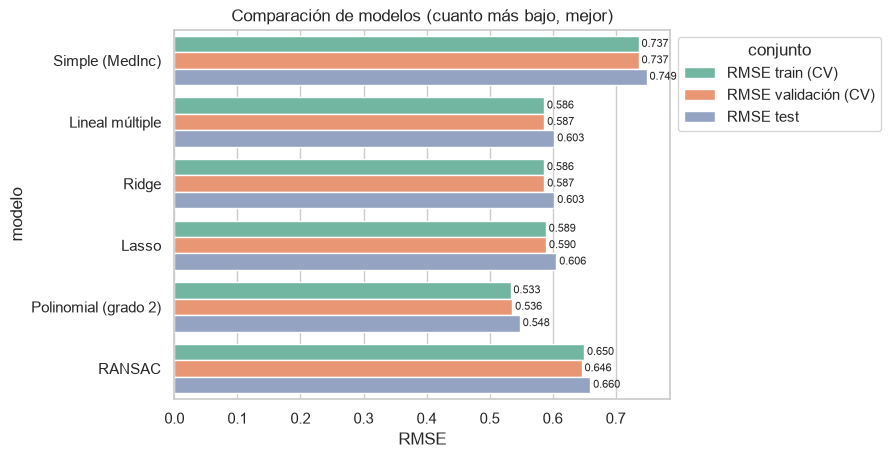

In [25]:
reporte_largo = (reporte[["RMSE train (CV)", "RMSE validación (CV)", "RMSE test"]]
                 .reset_index()
                 .melt(id_vars="modelo", var_name="conjunto", value_name="RMSE"))

ax = sns.barplot(data=reporte_largo, x="RMSE", y="modelo", hue="conjunto", palette="Set2")
ax.set_title("Comparación de modelos (cuanto más bajo, mejor)")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%.3f", fontsize=8, padding=2)
plt.show()

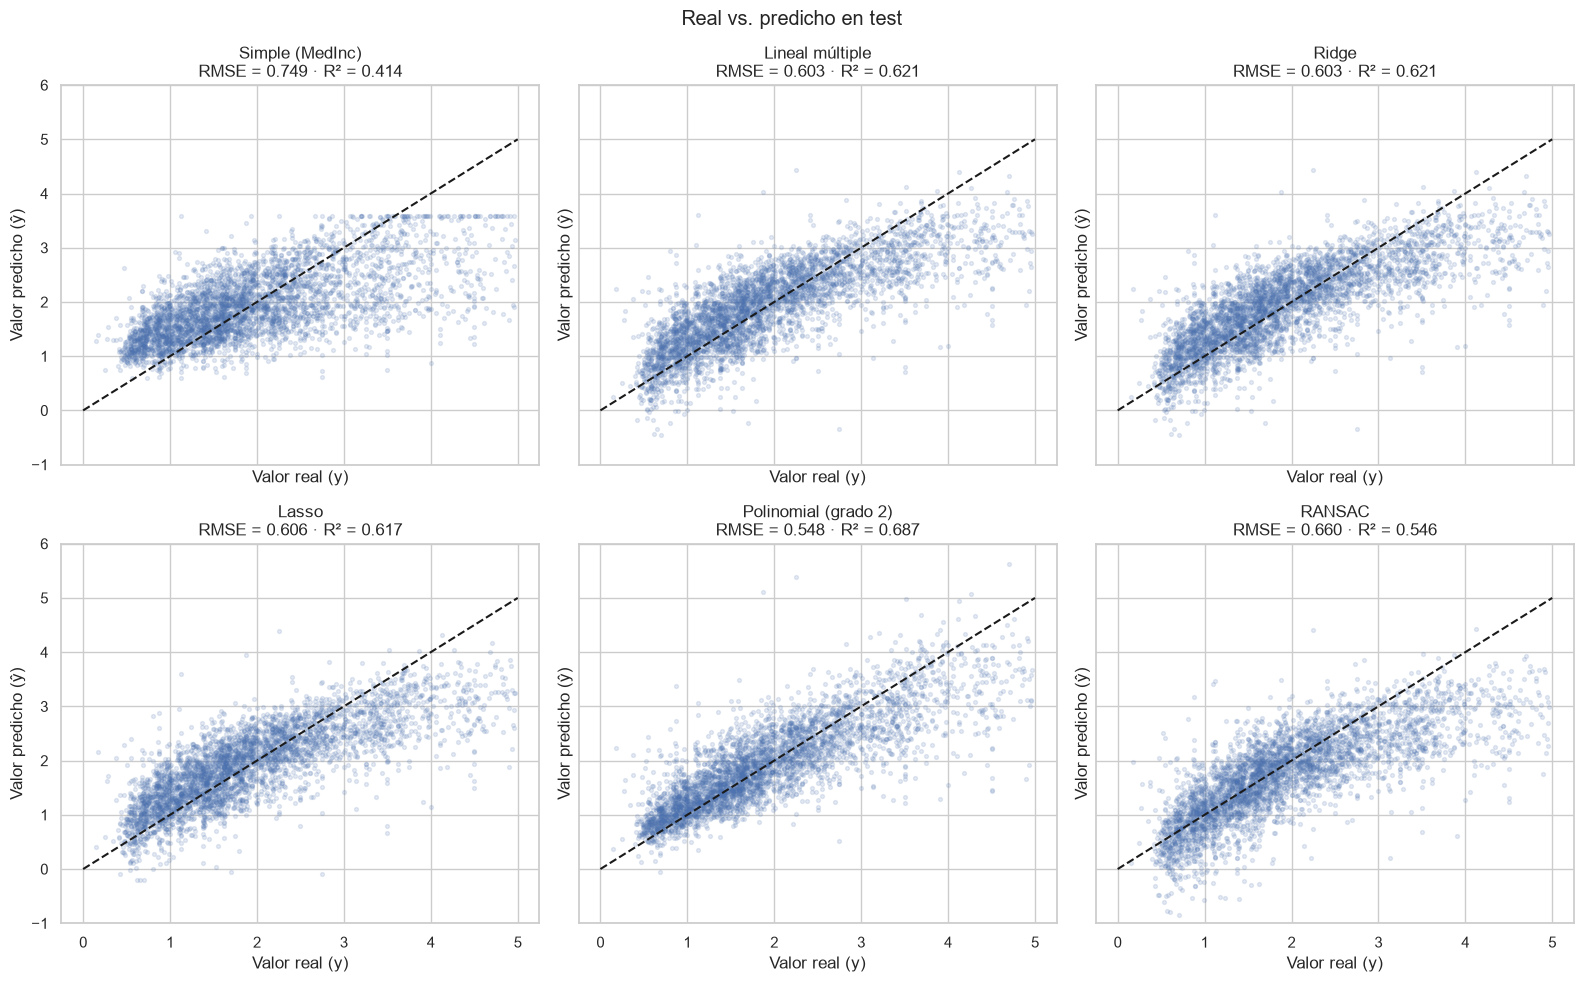

In [26]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10), sharex=True, sharey=True)
for (nombre, pred), ax in zip(predicciones.items(), axes.flat):
    ax.scatter(y_test, pred, alpha=0.15, s=8)
    ax.plot([0, 5], [0, 5], "k--")
    ax.set_title(f"{nombre}\nRMSE = {root_mean_squared_error(y_test, pred):.3f} · R² = {r2_score(y_test, pred):.3f}")
    ax.set_xlabel("Valor real (y)")
    ax.set_ylabel("Valor predicho (ŷ)")
ax.set_ylim(-1, 6)
fig.suptitle("Real vs. predicho en test")
plt.tight_layout()
plt.show()

> 🧪 **Prueba tú:** cambia `alpha` en Ridge y Lasso, el grado del polinomial o `residual_threshold` en RANSAC. ¿Cómo cambian los resultados?

---
## 8. 📋 Chuleta resumen

| Tarea | Código |
|---|---|
| Separar train/test (regresión) | `train_test_split(X, y, test_size=0.2, random_state=42)` (sin `stratify`) |
| Validación cruzada | `KFold(n_splits=5, shuffle=True, random_state=42)` |
| Regresión lineal | `LinearRegression()` → `.intercept_`, `.coef_` |
| Métricas de error | `mean_squared_error`, `root_mean_squared_error`, `mean_absolute_error`, `mean_absolute_percentage_error` |
| $R^2$ | `r2_score(y_real, y_pred)` |
| Ridge / Lasso | `Ridge(alpha=...)`, `Lasso(alpha=...)` |
| Regresión polinomial | `Pipeline([("poli", PolynomialFeatures(degree=2)), ("esc", StandardScaler()), ("reg", LinearRegression())])` |
| RANSAC | `RANSACRegressor(LinearRegression(), random_state=42)` |